In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
# Quantum Neural Network for Breast Cancer Classification

## Objective
Build and simulate a hybrid Quantum Neural Network (QNN)
for binary classification of breast cancer samples.

## Dataset
Breast Cancer Wisconsin (Diagnostic)

## Framework
PennyLane

## Quantum Architecture
- 4 qubits
- Angle encoding using RY rotations
- Trainable variational rotations
- CNOT entangling gates
- Pauli-Z expectation value measurement

## Classification
Benign vs Malignant

In [2]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 35.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 16.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 39.3 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 58.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 103.3 MB/s  0:00:00
  Attempting uninstall: autograd╺━━━━━━━━━━━━━━━━━━━━━━━━ 3/8 [diastatic-malt]2]
    Found existing installation: autograd 1.9.1━━━━━━━━━━━━━━━ 3/8 [diastatic-malt]
    Uninstalling autograd-1.9.1:━╺━━━━━━━━━━━━━━ 5/8 [autograd]t]
      Successfully uninstalled autograd-1.9.190m━━━━━━━━━━━━━━ 5/8 [autograd]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]/8 [pennylane]lightning]


In [3]:
import pennylane as qml

dev = qml.device("default.qubit", wires=4)

print("PennyLane works!")

PennyLane works!


In [ ]:
import pennylane as qml
from pennylane import numpy as np

import matplotlib.pyplot as plt
import pandas as pd

print("PennyLane version:", qml.__version__)

In [5]:
N_QUBITS = 4

dev = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

print("Quantum device initialized successfully.")
print("Number of qubits:", N_QUBITS)
#we Created a simulated quantum device with four qubits. This is where our circuit will run.

Quantum device initialized successfully.
Number of qubits: 4


In [7]:
@qml.qnode(dev)
def qnn_circuit(inputs, weights):

    # 1. Encode the input features
    for wire in range(N_QUBITS):
        qml.RY(inputs[wire], wires=wire)

    # 2. Apply trainable rotations
    for wire in range(N_QUBITS):
        qml.RY(weights[0, wire], wires=wire)

    # 3. Entangle neighboring qubits
    for wire in range(N_QUBITS - 1):
        qml.CNOT(wires=[wire, wire + 1])

    # 4. Measure the first qubit
    return qml.expval(qml.PauliZ(0))

In [8]:
sample_input = np.array(
    [0.3, 0.7, 0.2, 0.9]
)

initial_weights = np.array(
    [[0.1, 0.1, 0.1, 0.1]],
    requires_grad=True
)

output = qnn_circuit(sample_input, initial_weights)

print("Circuit output:", output)
#verifying the cercuit works

Circuit output: 0.9210609940028852


In [9]:
print(
    qml.draw(qnn_circuit)(
        sample_input,
        initial_weights
    )
)

0: ──RY(0.30)──RY(0.10)─╭●───────┤  <Z>
1: ──RY(0.70)──RY(0.10)─╰X─╭●────┤     
2: ──RY(0.20)──RY(0.10)────╰X─╭●─┤     
3: ──RY(0.90)──RY(0.10)───────╰X─┤     


In [10]:
gradient = qml.grad(
    lambda weights: qnn_circuit(sample_input, weights)
)(initial_weights)

print("Gradients:", gradient)
#Checkin that the circuit can learn ''calc gradient

Gradients: [[-3.89418342e-01  1.17961196e-16 -2.08166817e-17 -4.16333634e-17]]


In [11]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/ramykhelfaoui/dataset/data.csv


In [12]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/ramykhelfaoui/dataset/data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [13]:
FEATURES = [
    "concave points_mean",
    "radius_worst",
    "perimeter_worst",
    "concave points_worst"
]

TARGET = "diagnosis"

print("Selected features:")
print(df[FEATURES].head())

print("\nTarget distribution:")
print(df[TARGET].value_counts())

print("\nMissing values:")
print(df[FEATURES + [TARGET]].isnull().sum())

Selected features:
   concave points_mean  radius_worst  perimeter_worst  concave points_worst
0              0.14710         25.38           184.60                0.2654
1              0.07017         24.99           158.80                0.1860
2              0.12790         23.57           152.50                0.2430
3              0.10520         14.91            98.87                0.2575
4              0.10430         22.54           152.20                0.1625

Target distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values:
concave points_mean     0
radius_worst            0
perimeter_worst         0
concave points_worst    0
diagnosis               0
dtype: int64


In [20]:
import os

print(os.listdir("/kaggle/input/datasets/ramykhelfaoui/outputs"))

['X_test_final.csv', 'X_train_final.csv', 'evaluation_results.json', 'selected_features.json', 'test_indices.csv', 'train_indices.csv', 'y_test.csv', 'y_train.csv']


In [23]:
OUTPUT_DIR = "/kaggle/input/datasets/ramykhelfaoui/outputs"

In [24]:
import os
import json
import pandas as pd

# Load datasets
X_train = pd.read_csv(f"{OUTPUT_DIR}/X_train_final.csv")
X_test = pd.read_csv(f"{OUTPUT_DIR}/X_test_final.csv")

y_train = pd.read_csv(f"{OUTPUT_DIR}/y_train.csv")
y_test = pd.read_csv(f"{OUTPUT_DIR}/y_test.csv")

train_indices = pd.read_csv(f"{OUTPUT_DIR}/train_indices.csv")
test_indices = pd.read_csv(f"{OUTPUT_DIR}/test_indices.csv")

# Load JSON files
with open(f"{OUTPUT_DIR}/selected_features.json", "r") as file:
    selected_features = json.load(file)

with open(f"{OUTPUT_DIR}/evaluation_results.json", "r") as file:
    evaluation_results = json.load(file)

# Inspect
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nSelected features:")
print(selected_features)

print("\nClassical ML results:")
print(evaluation_results)

print("\nFeature columns:")
print(X_train.columns.tolist())

Training features: (455, 5)
Testing features: (114, 5)

Training labels: (455, 2)
Testing labels: (114, 2)

Selected features:
['concave points_mean', 'radius_worst', 'perimeter_worst', 'concave points_worst']

Classical ML results:
{'model_name': 'Logistic Regression', 'accuracy': 0.956140350877193, 'precision': 0.9512195121951219, 'recall': 0.9285714285714286, 'f1_score': 0.9397590361445783, 'training_time_seconds': 0.005498170852661133, 'confusion_matrix': [[70, 2], [3, 39]]}

Feature columns:
['Unnamed: 0', 'concave points_mean', 'radius_worst', 'perimeter_worst', 'concave points_worst']


In [25]:
print("Training labels:")
display(y_train.head())

print("Testing labels:")
display(y_test.head())

print("Training feature samples:")
display(X_train.head())

Training labels:


,Unnamed: 0,diagnosis
0,10,1
1,170,0
2,407,0
3,430,1
4,27,1


Testing labels:


,Unnamed: 0,diagnosis
0,120,0
1,250,1
2,375,0
3,99,1
4,455,0


Training feature samples:


,Unnamed: 0,concave points_mean,radius_worst,perimeter_worst,concave points_worst
0,10,-0.398175,0.579798,0.466908,-0.235744
1,170,-0.303075,-0.582459,-0.611934,-0.323208
2,407,-0.765459,-0.398622,-0.475431,-0.890825
3,430,1.213233,-0.000309,0.513776,1.977064
4,27,0.713767,1.012835,0.938517,0.501859


In [26]:
from sklearn.preprocessing import MinMaxScaler
from pennylane import numpy as np

# Remove the index column from features
X_train_clean = X_train.drop(columns=["Unnamed: 0"])
X_test_clean = X_test.drop(columns=["Unnamed: 0"])

# Extract labels
y_train_clean = y_train["diagnosis"].to_numpy()
y_test_clean = y_test["diagnosis"].to_numpy()

# Convert classical features into quantum rotation angles
angle_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_angles = angle_scaler.fit_transform(X_train_clean)
X_test_angles = angle_scaler.transform(X_test_clean)

# Convert to PennyLane-compatible arrays
X_train_qnn = np.array(X_train_angles)
X_test_qnn = np.array(X_test_angles)

y_train_qnn = np.array(y_train_clean)
y_test_qnn = np.array(y_test_clean)

print("Training data:", X_train_qnn.shape)
print("Testing data:", X_test_qnn.shape)

print("Training labels:", y_train_qnn.shape)
print("Testing labels:", y_test_qnn.shape)

print("\nFirst encoded sample:")
print(X_train_qnn[0])

Training data: (455, 4)
Testing data: (114, 4)
Training labels: (455,)
Testing labels: (114,)

First encoded sample:
[0.51886244 1.25842523 1.14827175 1.07688614]


In [28]:
import pennylane as qml

N_QUBITS = 4
N_LAYERS = 2

dev = qml.device("default.qubit", wires=N_QUBITS)

In [29]:
@qml.qnode(dev)
def qnn_circuit(inputs, weights):

    # Data encoding
    for wire in range(N_QUBITS):
        qml.RY(inputs[wire], wires=wire)

    # Trainable quantum layers
    for layer in range(N_LAYERS):

        for wire in range(N_QUBITS):
            qml.RY(weights[layer, wire], wires=wire)

        # Entangle neighboring qubits
        for wire in range(N_QUBITS - 1):
            qml.CNOT(wires=[wire, wire + 1])

    # Measurement
    return qml.expval(qml.PauliZ(0))

In [ ]:
what's happening:
1. We encode four input values using four RY gates.
2. We apply trainable rotations. Their angles are controlled by weights.
3. CNOT gates entangle neighboring qubits, allowing the circuit to learn relationships between them.
4. We measure qubit 0 using Pauli-Z.
The measurement returns an expectation value between -1 and +1.
- Near +1: qubit 0 is more likely to be measured as 0.
- Near -1: qubit 0 is more likely to be measured as 1.
This gives us a numerical output that we can convert into a binary prediction.

In [31]:
#test the cercuit our QNN circuit, without training it yet ''random wights'
initial_weights = np.random.uniform(
    low=-0.1,
    high=0.1,
    size=(N_LAYERS, N_QUBITS),
    requires_grad=True
)

sample_output = qnn_circuit(
    X_train_qnn[0],
    initial_weights
)

print("Circuit output:", sample_output)

Circuit output: 0.9059218685847016


In [32]:
print(qml.draw(qnn_circuit)(
    X_train_qnn[0],
    initial_weights
))

0: ──RY(0.52)──RY(-0.07)─╭●──RY(-0.02)────────────╭●──────────────┤  <Z>
1: ──RY(1.26)──RY(-0.02)─╰X─╭●──────────RY(-0.00)─╰X────────╭●────┤     
2: ──RY(1.15)──RY(-0.03)────╰X─────────╭●──────────RY(0.03)─╰X─╭●─┤     
3: ──RY(1.08)──RY(0.10)────────────────╰X──────────RY(0.07)────╰X─┤     


In [34]:
def loss_function(weights):

    predictions = np.stack([
        qnn_circuit(sample, weights)
        for sample in X_train_qnn
    ])

    expected_outputs = 1 - 2 * y_train_qnn

    return np.mean((predictions - expected_outputs) ** 2)

In [35]:
# Initialize trainable weights
weights = initial_weights

# Create optimizer
optimizer = qml.AdamOptimizer(stepsize=0.05)

EPOCHS = 50

loss_history = []

for epoch in range(EPOCHS):

    weights, current_loss = optimizer.step_and_cost(loss_function, weights)

    loss_history.append(current_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS} - Loss: {current_loss:.4f}")

Epoch 5/50 - Loss: 0.4434
Epoch 10/50 - Loss: 0.3566
Epoch 15/50 - Loss: 0.3568
Epoch 20/50 - Loss: 0.3254
Epoch 25/50 - Loss: 0.3179
Epoch 30/50 - Loss: 0.3197
Epoch 35/50 - Loss: 0.3122
Epoch 40/50 - Loss: 0.3100
Epoch 45/50 - Loss: 0.3097
Epoch 50/50 - Loss: 0.3077


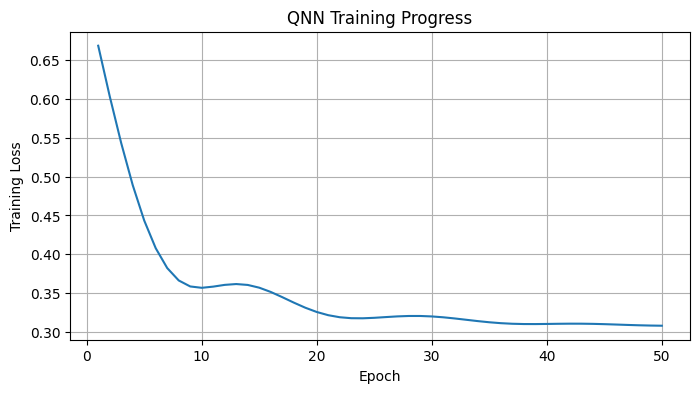

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("QNN Training Progress")
plt.grid(True)
plt.show()

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import time

# Generate QNN probabilities
start_time = time.time()

qnn_probabilities = np.array([
    (1 - qnn_circuit(sample, weights)) / 2
    for sample in X_test_qnn
])

qnn_training_time = time.time() - start_time

# Convert probabilities into binary predictions
qnn_predictions = (qnn_probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
qnn_accuracy = accuracy_score(y_test_qnn, qnn_predictions)
qnn_precision = precision_score(y_test_qnn, qnn_predictions)
qnn_recall = recall_score(y_test_qnn, qnn_predictions)
qnn_f1 = f1_score(y_test_qnn, qnn_predictions)

print("QNN Evaluation Results")
print("----------------------")
print(f"Accuracy:  {qnn_accuracy:.4f}")
print(f"Precision: {qnn_precision:.4f}")
print(f"Recall:    {qnn_recall:.4f}")
print(f"F1-score:  {qnn_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_qnn, qnn_predictions))

print("\nClassification Report:")
print(classification_report(y_test_qnn, qnn_predictions))

QNN Evaluation Results
----------------------
Accuracy:  0.9035
Precision: 0.9697
Recall:    0.7619
F1-score:  0.8533

Confusion Matrix:
[[71  1]
 [10 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.99      0.93        72
           1       0.97      0.76      0.85        42

    accuracy                           0.90       114
   macro avg       0.92      0.87      0.89       114
weighted avg       0.91      0.90      0.90       114



In [38]:
from sklearn.metrics import roc_auc_score, accuracy_score

# Predictions on training samples
train_probabilities = np.array([
    (1 - qnn_circuit(sample, weights)) / 2
    for sample in X_train_qnn
])

train_predictions = (train_probabilities >= 0.5).astype(int)

# Training accuracy
train_accuracy = accuracy_score(y_train_qnn, train_predictions)

# Test ROC-AUC
test_roc_auc = roc_auc_score(y_test_qnn, qnn_probabilities)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {qnn_accuracy:.4f}")
print(f"Testing ROC-AUC:   {test_roc_auc:.4f}")

Training Accuracy: 0.9253
Testing Accuracy:  0.9035
Testing ROC-AUC:   0.9871
